# P1.05 — Foreign residents: how many, who, where

**Question:** RQ3.2 (how has the foreign-resident population evolved and where is it located?). Context for RQ3.3
(immigration and prices, `p2_02`).

The series (`aima_foreigners`, INE) counts **foreign nationals holding a residence title on 31 December**, 2014 to 2023,
by municipality and nationality. It is not the foreign-born population (people who took Portuguese nationality are
not counted) and part of the 2023 jump may be administrative (`docs/data_quality.md`). Shares divide by INE's resident
population estimate, so they are indicative. Nothing later than 2023 exists at municipal level.

In [1]:
import pandas as pd

from pthousing.analysis import demography as dem
from pthousing.data import interim
from pthousing.viz import charts, dashboard, maps, style

style.apply_style()
panel = dashboard.load_panel()
aima = interim.read("aima_foreigners")
geometry = maps.municipality_geometry()
d23 = panel[panel["year"] == 2023].set_index("muni_code")
names = panel.drop_duplicates("muni_code").set_index("muni_code")[["muni_name", "district"]]
totals = dem.national_totals(panel)
by_nat = dem.nationality_totals(aima)
print(
    f"{len(aima):,} rows; years {aima['year'].min()}-{aima['year'].max()}; total 2023 {totals['foreign_residents_n'].iloc[-1]:,.0f}"
)

36,960 rows; years 2014-2023; total 2023 1,044,238


## Step 1 — The rise
The count rose 2.7 times in nine years, with two steps: 2017-2019 and 2022-2023. The foreign share of residents
rose faster in urban municipalities, where most of them live.

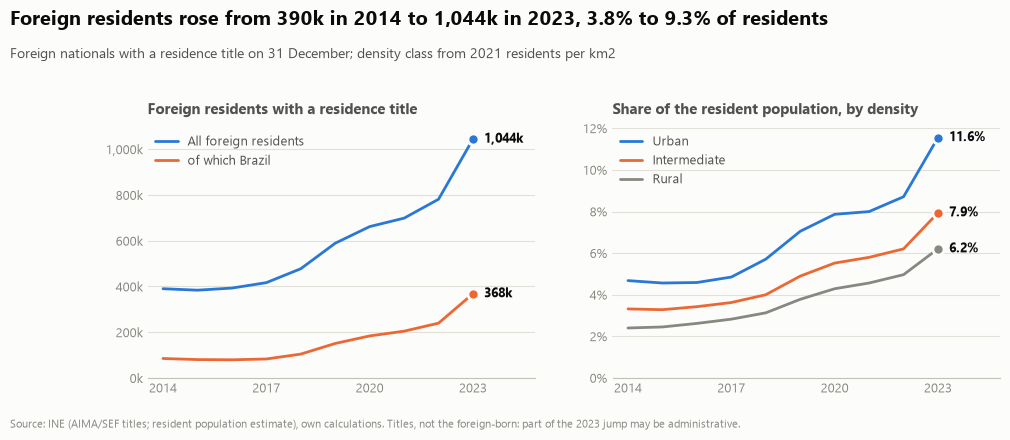

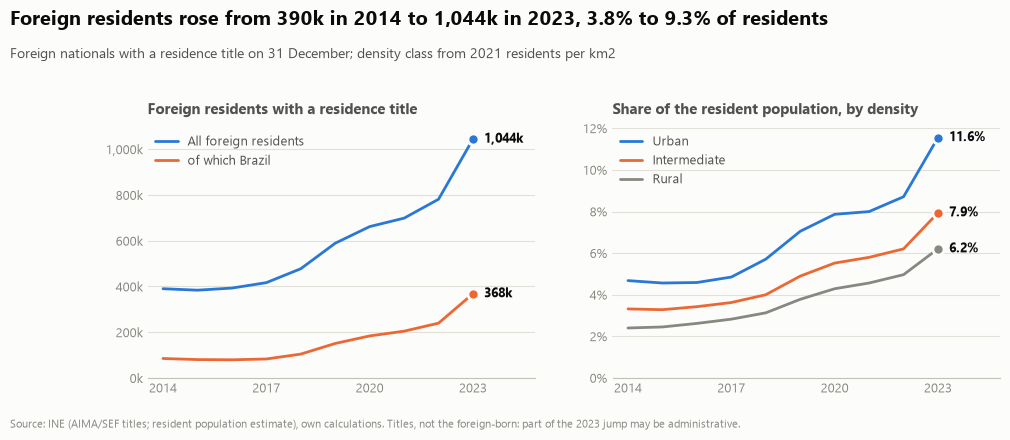

In [2]:
classes = (
    panel.dropna(subset=["foreign_residents_n"])
    .groupby(["year", "density_class"])[["foreign_residents_n", "population_n"]]
    .sum()
)
share_by_class = (100 * classes["foreign_residents_n"] / classes["population_n"]).unstack()
fig = charts.foreign_residents_trend(totals, by_nat["br"], share_by_class)
style.save_fig(fig, "p1", "foreign_residents_trend")
fig

In [3]:
growth = pd.DataFrame(
    {
        f"{a}-{b}": dem.growth_contribution(panel, a, b)
        for a, b in ((2014, 2019), (2019, 2022), (2022, 2023), (2014, 2023))
    }
).T.round(1)
nat_growth = pd.DataFrame(
    {
        "foreign_2014": by_nat.loc[2014],
        "foreign_2019": by_nat.loc[2019],
        "foreign_2023": by_nat.loc[2023],
    }
)
nat_growth["multiple_2014_2023"] = nat_growth["foreign_2023"] / nat_growth["foreign_2014"]
nat_growth["share_of_2023_total_pct"] = (
    100 * nat_growth["foreign_2023"] / nat_growth.loc["total", "foreign_2023"]
)
nat_growth.index = [dem.NATIONALITY_NAMES.get(i, "All foreign residents") for i in nat_growth.index]
nat_growth = nat_growth.round(2).sort_values("foreign_2023", ascending=False)
style.save_table(totals.round(2).reset_index(), "p1", "foreign_residents_totals")
style.save_table(
    nat_growth.reset_index(names="nationality"), "p1", "foreign_residents_by_nationality"
)
print(growth.to_string())
nat_growth

           population_change_n  foreign_change_n  other_change_n  foreign_share_of_change_pct
2014-2019             -19726.0          198863.0       -218589.0                          NaN
2019-2022             554309.0          192271.0        362038.0                         34.7
2022-2023             274643.0          262991.0         11652.0                         95.8
2014-2023             809226.0          654125.0        155101.0                         80.8


,foreign_2014,foreign_2019,foreign_2023,multiple_2014_2023,share_of_2023_total_pct
All foreign residents,390113,588976,1044238,2.68,100.00
All other,101640,221460,387442,3.81,37.10
Brazil,85288,150919,368391,4.32,35.28
Angola,19478,22592,55564,2.85,5.32
Cabo Verde,40563,37110,48792,1.20,4.67
United Kingdom,16559,34358,47407,2.86,4.54
Guinea-Bissau,17728,18780,32523,1.83,3.11
China,21057,27810,28123,1.34,2.69
São Tomé and Príncipe,10028,10078,26460,2.64,2.53
Ukraine,37809,29706,23499,0.62,2.25


## Step 2 — Where
The share of residents in 2023 and how much it rose since 2019, in percentage points of the resident population.
Hatched: no count.

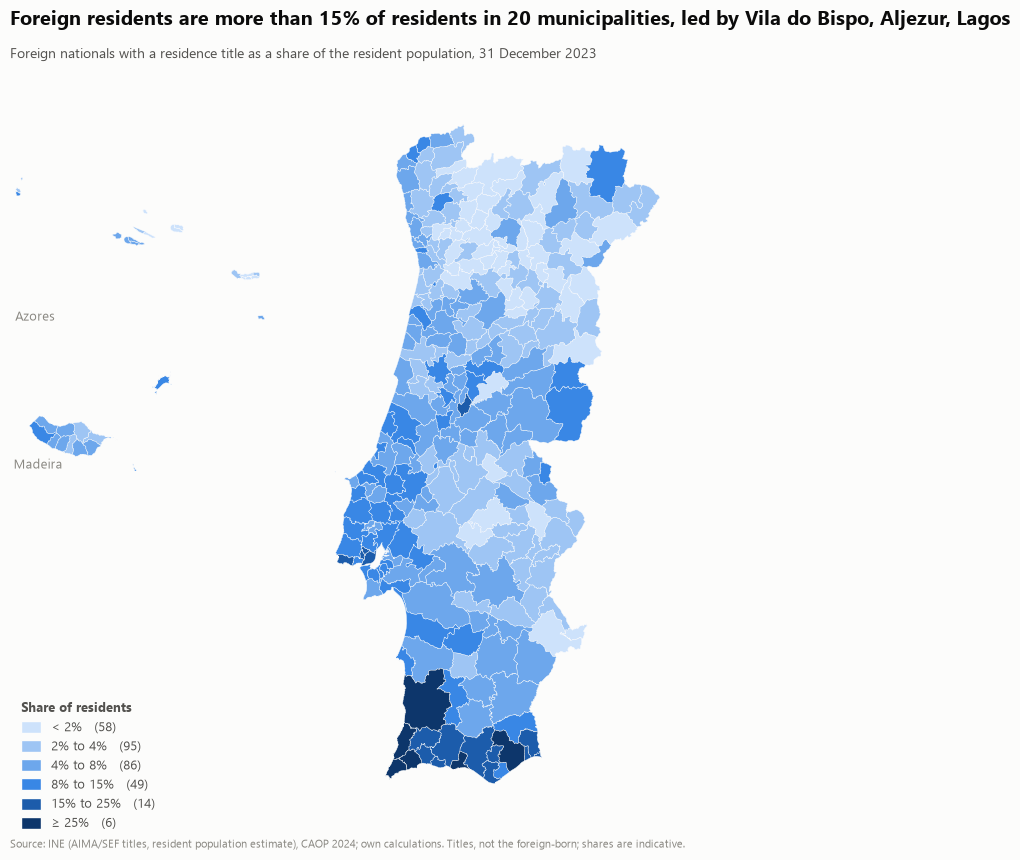

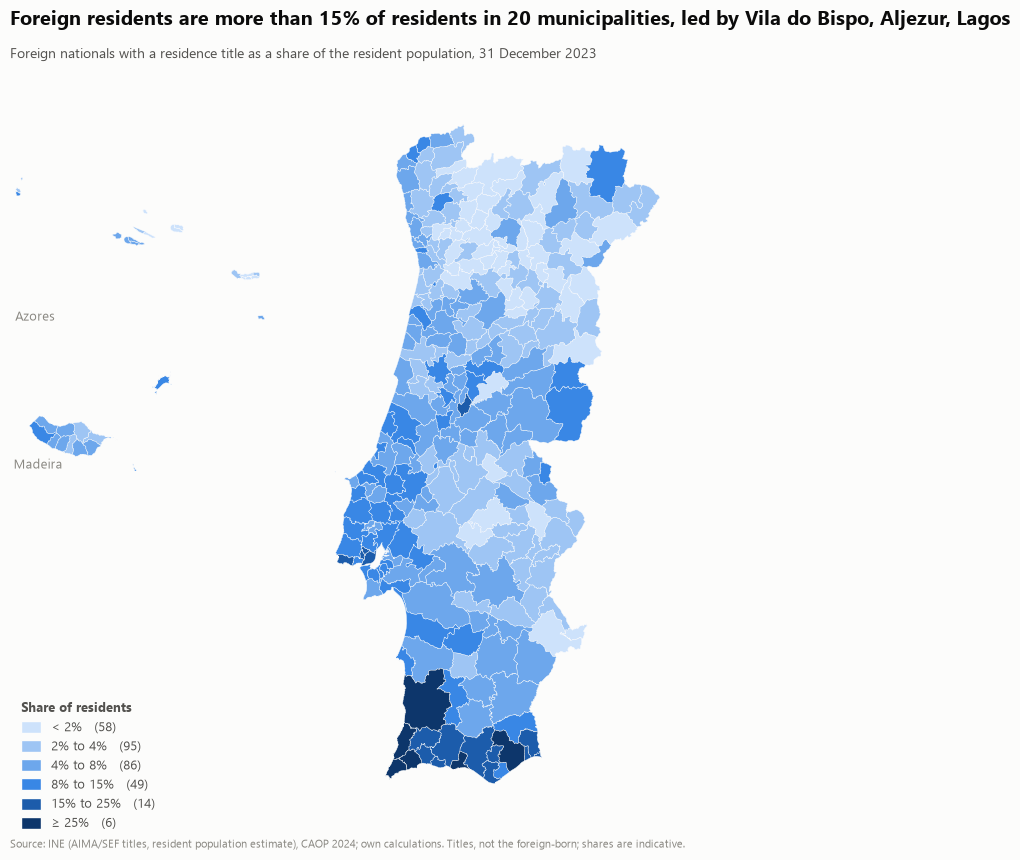

In [4]:
share23 = d23["foreign_residents_pct"]
n20 = int((share23 > 20).sum())
lead = names.join(share23).sort_values("foreign_residents_pct").tail(3)["muni_name"].tolist()[::-1]
fig = maps.choropleth(
    share23, geometry, [2, 4, 8, 15, 25], style.SEQUENTIAL_6,
    f"Foreign residents are more than 15% of residents in {int((share23 > 15).sum())} municipalities, led by {', '.join(lead)}",
    "Foreign nationals with a residence title as a share of the resident population, 31 December 2023",
    "Source: INE (AIMA/SEF titles, resident population estimate), CAOP 2024; own calculations. Titles, not the foreign-born; shares are indicative.",
    "Share of residents", fmt="{:g}", suffix="%",
)  # fmt: skip
style.save_fig(fig, "p1", "foreign_residents_share_map_2023")
fig

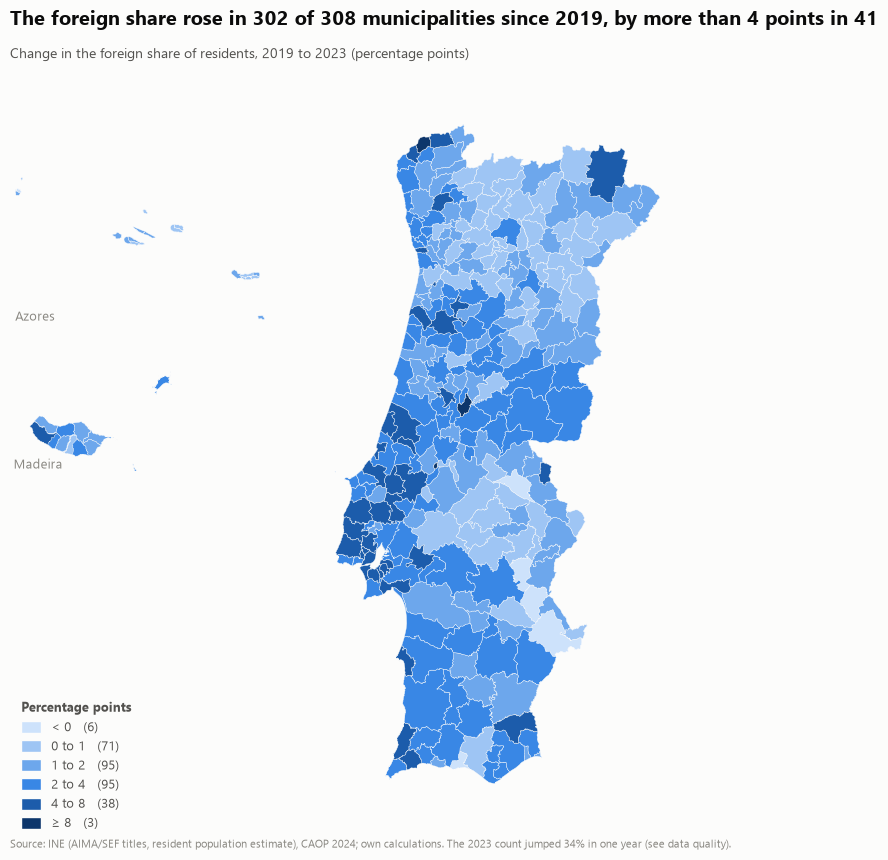

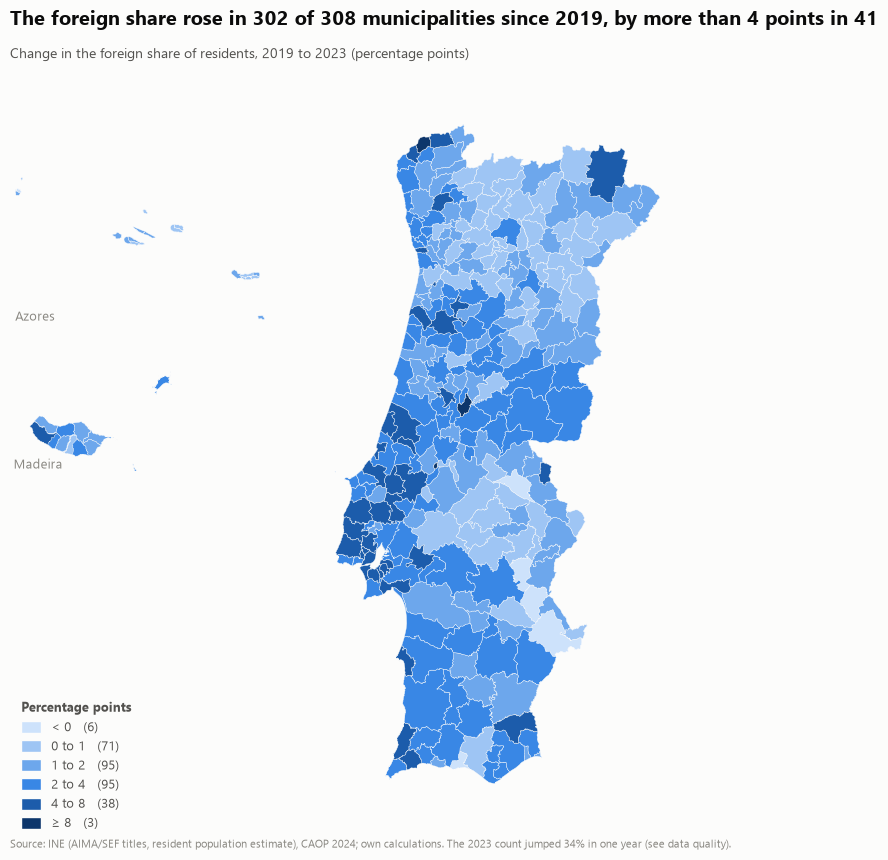

In [5]:
wide = panel[panel["year"].isin([2019, 2023])].pivot(
    index="muni_code", columns="year", values="foreign_residents_pct"
)
rise = (wide[2023] - wide[2019]).dropna()
fig = maps.choropleth(
    rise, geometry, [0, 1, 2, 4, 8], style.SEQUENTIAL_6,
    f"The foreign share rose in {int((rise > 0).sum())} of {len(rise)} municipalities since 2019, by more than 4 points in {int((rise > 4).sum())}",
    "Change in the foreign share of residents, 2019 to 2023 (percentage points)",
    "Source: INE (AIMA/SEF titles, resident population estimate), CAOP 2024; own calculations. The 2023 count jumped 34% in one year (see data quality).",
    "Percentage points", fmt="{:g}", suffix="",
)  # fmt: skip
style.save_fig(fig, "p1", "foreign_residents_change_map_2019_2023")
fig

### Concentration and type of place, 2023
Share of all foreign residents against the share of the population, by municipality group.

In [6]:
conc = dem.concentration(panel, 2023).round(1)
dist = pd.concat(
    {
        "density": dem.group_distribution(panel, 2023, "density_class"),
        "coast": dem.group_distribution(panel, 2023, "coast_class"),
        "district": dem.group_distribution(panel, 2023, "district").head(6),
    },
    names=["dimension", "group"],
).round(1)
style.save_table(conc, "p1", "foreign_residents_concentration_2023")
style.save_table(dist.reset_index(), "p1", "foreign_residents_by_place_2023")
print(conc.to_string())
dist

   top_municipalities  foreign_share_of_total_pct  population_share_of_total_pct
0                   1                        15.5                            5.9
1                   5                        32.5                           16.0
2                  10                        45.5                           23.9
3                  30                        70.5                           44.6


foreign_residents_n  population_n  \
dimension group                                             
density   urban                    613479.0     5307120.0   
          intermediate             295720.0     3723393.0   
          rural                    135039.0     2173834.0   
coast     coast                    552665.0     5015736.0   
          inland                   273763.0     5027032.0   
          estuary                  217810.0     1161579.0   
district  Lisboa                   431677.0     2594574.0   
          Faro                     125424.0      563923.0   
          Setúbal                  106353.0      974784.0   
          Porto                     97155.0     1878373.0   
          Leiria                    43495.0      502691.0   
          Braga                     41808.0      885356.0   

                        foreign_share_of_total_pct  \
dimension group                                      
density   urban                               58.7   
          intermediate                        28.3   
          rural                               12.9   
coast     coast                               52.9   
          inland                              26.2   
          estuary                             20.9   
district  Lisboa                              41.3   
          Faro                                12.0   
          Setúbal                             10.2   
          Porto                                9.3   
          Leiria                               4.2   
          Braga                                4.0   

                        population_share_of_total_pct  foreign_share_pct  
dimension group                                                           
density   urban                                  47.4               11.6  
          intermediate                           33.2                7.9  
          rural                                  19.4                6.2  
coast     coast                                  44.8               11.0  
          inland                                 44.9                5.4  
          estuary                                10.4               18.8  
district  Lisboa                                 23.2               16.6  
          Faro                                    5.0               22.2  
          Setúbal                                 8.7               10.9  
          Porto                                  16.8                5.2  
          Leiria                                  4.5                8.7  
          Braga                                   7.9                4.7

In [7]:
top = (
    names.join(d23[["foreign_residents_n", "population_n", "foreign_residents_pct"]])
    .sort_values("foreign_residents_n", ascending=False)
    .reset_index()
)
style.save_table(top.round(2), "p1", "foreign_residents_by_municipality_2023")
top.head(10)

,muni_code,muni_name,district,foreign_residents_n,population_n,foreign_residents_pct
0,1106,Lisboa,Lisboa,162306.0,655542.0,24.759054
1,1111,Sintra,Lisboa,63222.0,432915.0,14.603791
2,1105,Cascais,Lisboa,42824.0,241537.0,17.729789
3,1115,Amadora,Lisboa,35858.0,196563.0,18.242497
4,1312,Porto,Porto,35651.0,267236.0,13.340643
5,1107,Loures,Lisboa,32264.0,227301.0,14.194394
6,1116,Odivelas,Lisboa,32250.0,180033.0,17.913383
7,1503,Almada,Setúbal,25713.0,197221.0,13.037658
8,0808,Loulé,Faro,22725.0,91363.0,24.873308
9,1510,Seixal,Setúbal,21890.0,188623.0,11.605159


## Step 3 — Who lives where
Nationalities settle in different places: the share of each living in the three districts with most foreign residents.

['Lisboa', 'Faro', 'Setúbal']


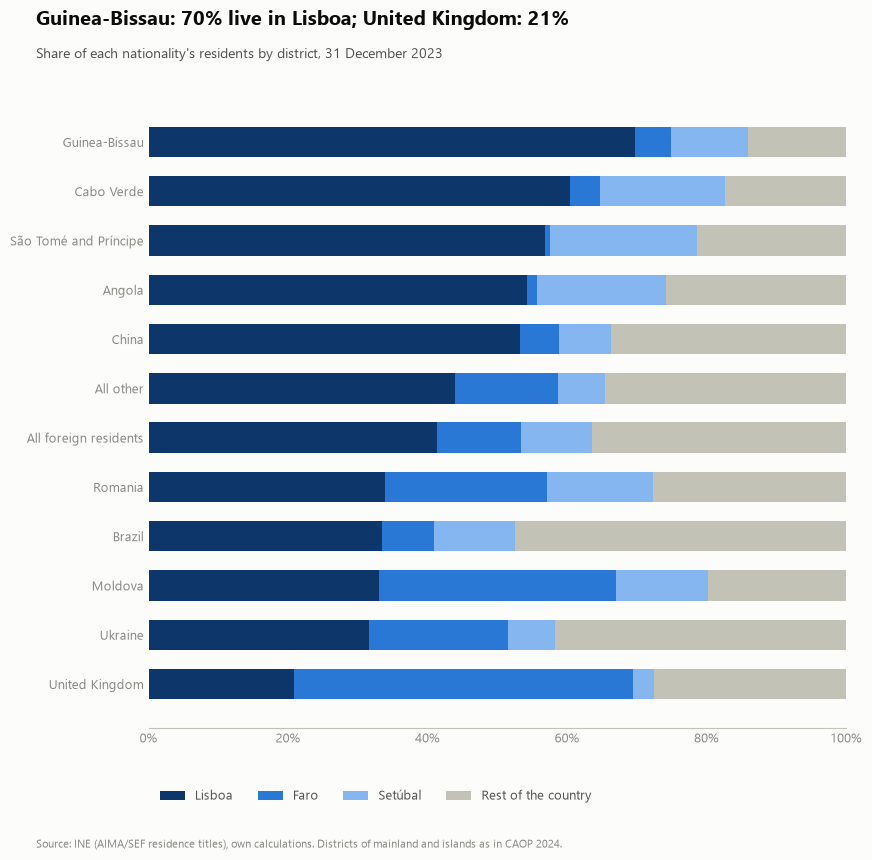

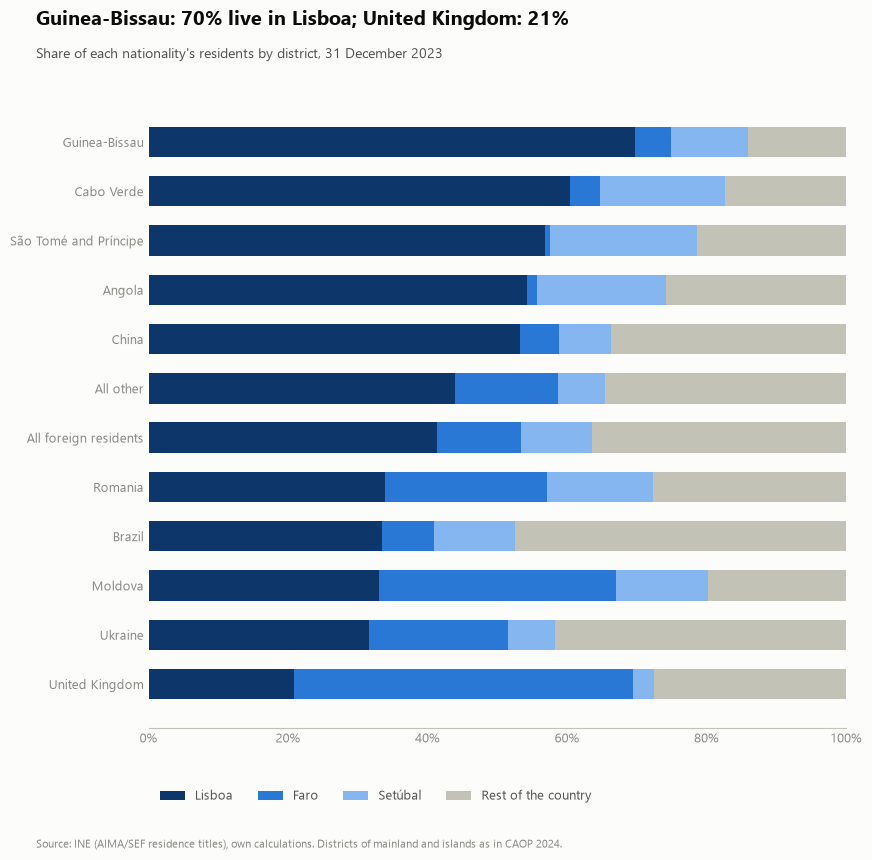

In [8]:
districts = dem.group_distribution(panel, 2023, "district").index[:3].tolist()
location = dem.nationality_location(aima, panel, 2023, "district", districts)
labels = {d: d for d in districts} | {"other": "Rest of the country"}
lnames = dem.NATIONALITY_NAMES | {"total": "All foreign residents"}
fig = charts.nationality_location_bars(location, labels, lnames)
style.save_fig(fig, "p1", "foreign_residents_location_by_nationality")
style.save_table(location.round(1).reset_index(), "p1", "foreign_residents_location_by_nationality")
print(districts)
fig

## Key numbers

In [9]:
t = totals
print(
    f"{t['foreign_residents_n'].iloc[0]:,.0f} (2014) -> {t.loc[2019, 'foreign_residents_n']:,.0f} (2019) -> {t.loc[2022, 'foreign_residents_n']:,.0f} (2022) -> {t.loc[2023, 'foreign_residents_n']:,.0f} (2023); "
    f"share {t['foreign_share_pct'].iloc[0]:.1f}% -> {t['foreign_share_pct'].iloc[-1]:.1f}%"
)
g = growth
print(
    f"2019-2023: population {g.loc['2019-2022', 'population_change_n'] + g.loc['2022-2023', 'population_change_n']:,.0f}, foreign residents {g.loc['2019-2022', 'foreign_change_n'] + g.loc['2022-2023', 'foreign_change_n']:,.0f}; "
    f"2014-2019 population {g.loc['2014-2019', 'population_change_n']:,.0f} with foreign residents {g.loc['2014-2019', 'foreign_change_n']:,.0f}"
)
print(conc.to_string())
print(
    f"municipalities above 15%: {int((share23 > 15).sum())}, above 20%: {n20}; max {share23.max():.0f}% ({top.sort_values('foreign_residents_pct').iloc[-1]['muni_name']})"
)

390,113 (2014) -> 588,976 (2019) -> 781,247 (2022) -> 1,044,238 (2023); share 3.8% -> 9.3%
2019-2023: population 828,952, foreign residents 455,262; 2014-2019 population -19,726 with foreign residents 198,863
   top_municipalities  foreign_share_of_total_pct  population_share_of_total_pct
0                   1                        15.5                            5.9
1                   5                        32.5                           16.0
2                  10                        45.5                           23.9
3                  30                        70.5                           44.6
municipalities above 15%: 20, above 20%: 11; max 38% (Vila do Bispo)
